# 08 DINÂMICA DE SUB-ESCALA: CANAIS BASAIS LAGRANGIANOS, MIGRAÇÃO DA LINHA DE ATERRAMENTO (INSAR VS. FLUTUAÇÃO) E FRATURAMENTO EM FÓTONS ATL03

Este caderno reúne as três frentes de modelagem física de alta resolução implementadas em `pipelines/canais/`, `pipelines/gl_migration/` e `pipelines/melange/`:

1. **Aprofundamento Lagrangiano de Canais Basais Subglaciais (`pipelines/canais/c01..c07`):**
   - *Física:* Plumas de água de fusão subglacial aquecida sobem ao longo da base inclinada das plataformas, escavando canais subglaciais invertidos de $0{,}5\text{ a }3\text{ km}$ de largura (Chartrand et al., 2024; Lowery et al., 2025; Zinck et al., 2026). Pela relaxação hidrostática local, um canal basal produz uma depressão superficial de profundidade $D = h_{\text{quilha}} - h_{\text{canal}}$. Como $D$ é medido entre o centro do canal e as cristas laterais **na mesma passagem orbital**, erros de maré, DAC e geoide cancelam-se exatamente!
   - *Rastreamento Lagrangiano e Viés Inter-Trilha (`c04_lagrangiano.py` e `c05_vies_trilhas.py`):* Como o fluxo advecta os canais oblíquos através de seções fixas (na PIG o gelo percorre $\sim 27\text{ km}$ em 7 anos), transportamos cada seção detectada no tempo $t_i$ por integração Runge–Kutta de 2ª ordem (RK2, passo de $15\text{ dias}$) até interceptar outra seção no tempo $t_j$ dentro de $R_{\text{par}} = 400\text{ m}$ (com filtro de erro cinemático $\sigma_u \Delta t < R_{\text{par}}/2$), estimando a taxa de aprofundamento $\Delta D / \Delta t$ (e em espessura equivalente $\times 9{,}34$) com efeitos fixos por seção para eliminar viés geométrico entre RGTs distintas.

2. **Migração da Linha de Aterramento: Condição Hidrostática de Flutuação vs. Multi-Sensor DInSAR (`pipelines/gl_migration/p01..p14`):**
   - *Física (Altura Acima da Flutuação — HAF):* A condição hidrostática de desaterramento define $\text{HAF}(s) = H(s) + (\rho_w / \rho_i)\,b(s)$ ao longo de cada linha de fluxo $s$. Se o recuo da linha de aterramento fosse governado puramente pelo afinamento hidrostático sem intrusão de água pressurizada nem mudança de flexão, a velocidade de recuo prevista seria:
     $$v_{\text{prev}} = -\frac{\partial h / \partial t}{\partial \text{HAF} / \partial s}$$
   - *Modelo de Efeitos Fixos com Desvio por Sensor InSAR (`p14_recuo_com_vies_sensor.py`):* Diferentes constelações SAR (Sentinel-1 CCI/NSIDC/Andersen, COSMO-SkyMed/CSK e ICEYE) amostram a zona de flexão com geometrias, comprimentos de onda (banda C vs. banda X) e limiares de fase distintos, divergindo em até $\sim 1\text{ km}$ na mesma época. Ajustamos o modelo em painel robusto (Huber + Block Bootstrap de $10\text{ km}$):
     $$s_{f,i} = a_f + v_{\text{recuo}}(t_i - 2021) + o_{k(i)} + \varepsilon_{f,i}$$
     sob duas hipóteses de ligação temporal ($H_1$: família Sentinel-1 compartilha desvio; $H_2$: sensores de banda X de alta resolução $\text{CSK} \approx \text{ICEYE}$).

3. **Dinâmica de Fraturamento e Mélange na Margem de Cisalhamento da Thwaites (`pipelines/melange/m01..m10`):**
   - *Pergunta física (Wild et al., 2022; Chartrand et al., 2024; Wang et al., 2025):* O aumento observado de fendas e rugosidade superficial na margem de cisalhamento da TEIS decorre de **geração de dano mecânico novo *in situ*** ou da **advecção de gelo já fraturado vindo de montante**?
   - *Método com Fótons ATL03 (`m06`–`m09`):* Como as trilhas RGT 5 e RGT 1079 cruzam a margem da TEIS quase paralelas ao vetor velocidade ($1^\circ$ e $10^\circ$), retroadvectamos todas as fendas detectadas na nuvem de fótons ATL03 e a rugosidade do ATL06 para a configuração material de referência $T_{\text{ref}} = 2019{,}0$, comparando a taxa de persistência Lagrangiana contra um modelo nulo de fase uniforme e testando a evolução da densidade de fendas dentro dos mesmos blocos materiais de $2\text{ km}$.

### Roteiro do caderno
| Seção | Fundamentação | Aplicação em código | Pipeline |
|---|---|---|---|
| 1 | Canais basais e rastreamento Lagrangiano de seções | taxas de aprofundamento com efeito fixo de seção; comparação com Lowery et al. (2025) | `pipelines/canais/` |
| 2 | Migração da linha de aterramento: flutuação (HAF) × InSAR | perfil sintético de HAF; recuo previsto × observado; resposta de maré no "apoiado"; vieses inter-sensor | `pipelines/gl_migration/` |
| 3 | Fraturamento: dano novo × advecção de gelo fraturado | densidade de fendas em blocos materiais (ATL03) e rugosidade (ATL06) | `pipelines/melange/` |
| 4 | Síntese | — | — |

In [1]:
# ── Configuração comum do caderno ─────────────────────────────────────────────
# Localiza a raiz do repositório (a pasta que contém o pacote `thwaites/`), torna o
# pacote importável mesmo sem `pip install -e .` e aponta DATA_DIR para as tabelas
# resumidas que alimentam todas as figuras. Basta executar o caderno de cima para baixo.
import sys
import json
from pathlib import Path

_candidatas = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidatas if (p / "thwaites").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Execute o caderno a partir de dentro do repositório (pasta com 'thwaites/').")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
DATA_DIR = REPO_ROOT / "notebooks" / "dados_resumo"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9, "axes.titlesize": 9.5,
})
# Mensagens de log da biblioteca: só erros (os cadernos não chamam setup_logging()).
try:
    from loguru import logger as _logger
    import thwaites.logging as _tlog
    _logger.remove()
    _logger.add(sys.stderr, level="ERROR", format="{level}: {message}")
    _tlog._CONFIGURED = True
except ImportError:
    pass

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
CORES = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E",
         "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
print(f"Tabelas resumidas disponíveis em dados_resumo/: {len(list(DATA_DIR.glob('*')))}")

Tabelas resumidas disponíveis em dados_resumo/: 74


---
## 1. Canais Basais: Aprofundamento Lagrangiano por Seção

A tabela abaixo dá a taxa de variação da profundidade superficial $D$ dos canais (`taxa_fe`, m/ano de superfície), estimada com efeito fixo por seção para eliminar o viés entre trilhas, e a conversão para contraste de espessura (`taxa_fe_H` ≈ 9,34 × `taxa_fe`). Valores positivos indicam canal **aprofundando**, ou seja, mais derretimento no canal que nas quilhas.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

can_res = pd.read_csv(DATA_DIR / "canais_resumo_plataformas.csv")
can_fe = pd.read_csv(DATA_DIR / "canais_lagrangiano_efeito_secao.csv")
gl_prev = pd.read_csv(DATA_DIR / "gl_migracao_previsao_vs_insar.csv")
gl_vies = pd.read_csv(DATA_DIR / "gl_migracao_recuo_vies_sensor.csv")
gl_mare_ap = pd.read_csv(DATA_DIR / "open_check_7_apoiado_com_mare.csv")
mel_fendas = pd.read_csv(DATA_DIR / "melange_fendas_atl03_advecao.csv")
mel_rug = pd.read_csv(DATA_DIR / "melange_rugosidade_atl06_advecao.csv")

# 1. Tabela de aprofundamento Lagrangiano dos canais basais com efeito fixo de seção
can_fe.set_index(["plataforma", "classe"]).round(3)

n_pares  n_secoes  n_mesma_secao  n_blocos  taxa_fe     lo     hi  taxa_mesma_secao  taxa_agrupada  taxa_fe_H    lo_H    hi_H
plataforma  classe                                                                                                                                        
Cosgrove    lento <1 km/a       5737        91           3414        21   -0.022 -0.064  0.013            -0.029         -0.020     -0.209  -0.599   0.123
            rápido >=1 km/a       62        27              7        10   -0.159 -2.998  0.032               NaN         -0.122     -1.485 -27.992   0.295
Crosson     lento <1 km/a        771        90            296        22   -0.169 -0.475  1.429            -0.218         -0.346     -1.580  -4.438  13.341
            rápido >=1 km/a      365        81             71        19   -1.033 -3.064  2.300            -0.590         -0.885     -9.646 -28.603  21.472
Dotson      lento <1 km/a       1357        37            858        15   -0.110 -0.385  0.007            -0.106         -0.103     -1.027  -3.591   0.065
Pine_Island lento <1 km/a       3810        74           1850        16    0.253  0.102  0.392             0.216          0.307      2.360   0.957   3.658
            rápido >=1 km/a     1665       226             22        29    1.878 -1.604  9.492             8.376         -0.564     17.533 -14.978  88.619

**Leitura da tabela.**
- O único resultado com IC95% inteiramente de um lado do zero é a **Pine Island lenta** (< 1 km/ano): canais aprofundando ~0,25 m/ano na superfície, ~2,4 m/ano em espessura. É o sinal de canais em crescimento ativo onde o gelo se move devagar o suficiente para as mesmas seções serem revisitadas.
- Nos setores **rápidos** (≥ 1 km/ano), os ICs são enormes. Poucas seções são revisitadas na mesma posição material (`n_mesma_secao` baixo) e a advecção desloca os canais entre trilhas.
- Cosgrove e Dotson lentas mostram canais estáveis ou levemente rasos (IC contendo zero ou quase).

### 1.1 Aplicação: os canais do ICESat-2 batem com o mapa de CryoSat-2 de Lowery et al. (2025)?
Comparamos, seção a seção na Pine Island, o contraste de derretimento implicado pelo aprofundamento ($\Delta m_{\text{IS2}} = 9{,}34\,dD/dt$) com o contraste canal − quilhas do mapa de derretimento de Lowery et al. (2025):

,Valor
Seções com as duas medidas,96.000
Correlação de Pearson,0.012
ρ de Spearman,0.095
p (Spearman),0.355
Concordância de sinal (%),53.125
Mediana Δm ICESat-2 (m/ano),1.411
Mediana Δm Lowery (m/ano),0.094


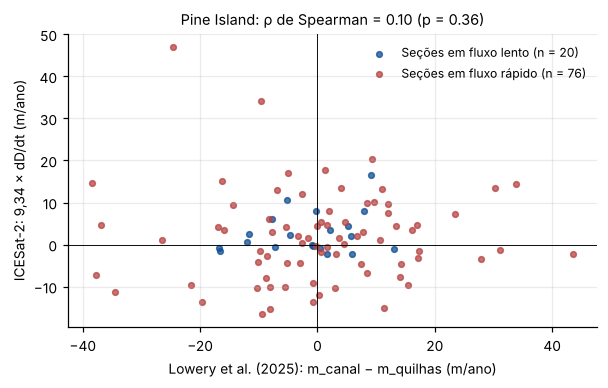

In [3]:
from scipy.stats import spearmanr

low = pd.read_csv(DATA_DIR / "canais_comparacao_lowery.csv")
par = low.dropna(subset=["dm_is2", "dm_lowery"])
rho_s, p_s = spearmanr(par["dm_is2"], par["dm_lowery"])

fig, ax = plt.subplots(figsize=(5.6, 3.6))
for cl, cor in [("lento", "#0F4D92"), ("rápido", "#B64342")]:
    g = par[par["classe"] == cl]
    ax.scatter(g["dm_lowery"], g["dm_is2"], s=14, color=cor, alpha=0.75, label=f"Seções em fluxo {cl} (n = {len(g)})")
ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel("Lowery et al. (2025): m_canal − m_quilhas (m/ano)"); ax.set_ylabel("ICESat-2: 9,34 × dD/dt (m/ano)")
ax.set_title(f"Pine Island: ρ de Spearman = {rho_s:.2f} (p = {p_s:.2f})"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
pd.Series({"Seções com as duas medidas": len(par), "Correlação de Pearson": np.corrcoef(par["dm_is2"], par["dm_lowery"])[0, 1],
           "ρ de Spearman": rho_s, "p (Spearman)": p_s,
           "Concordância de sinal (%)": 100 * np.mean(np.sign(par["dm_is2"]) == np.sign(par["dm_lowery"])),
           "Mediana Δm ICESat-2 (m/ano)": par["dm_is2"].median(), "Mediana Δm Lowery (m/ano)": par["dm_lowery"].median()}).round(3).to_frame("Valor")

**Leitura (resultado negativo, reportado como tal).** Seção a seção, **não há concordância**: correlação ~0 e concordância de sinal de ~50%, o esperado por acaso. Isso não invalida nenhum dos dois produtos, porque as grandezas e os períodos diferem:
1. O ICESat-2 mede a **variação temporal** da profundidade do canal. Um canal em equilíbrio, com derretimento intenso compensado pela convergência de fluxo, tem $dD/dt \approx 0$ mesmo com alto contraste de derretimento;
2. Lowery et al. (2025) mapeiam o derretimento **médio** de um período anterior com CryoSat-2 *swath*, em resolução diferente;
3. As taxas por seção têm incertezas de metros por ano (ICs da tabela anterior).

A conclusão útil é metodológica: **a taxa de aprofundamento de canais medida por altimetria de trilha não serve como proxy do contraste de derretimento canal–quilha** na escala de seção. O produto de canais deste estudo é interpretado apenas em agregados por plataforma (tabela abaixo).

In [4]:
can_res.set_index("plataforma")[["n_secoes", "D_med", "dDdt_L", "dDdt_L_lo", "dDdt_L_hi", "frac_aprofunda", "frac_rasa", "amp_saz"]].rename(columns={
    "n_secoes": "Seções", "D_med": "Profundidade D mediana (m)", "dDdt_L": "dD/dt Lagrangiano (m/ano)",
    "dDdt_L_lo": "IC95% inf.", "dDdt_L_hi": "IC95% sup.", "frac_aprofunda": "Fração aprofundando",
    "frac_rasa": "Fração ficando rasa", "amp_saz": "Amplitude sazonal (m)"}).round(3)

,Seções,Profundidade D mediana (m),dD/dt Lagrangiano (m/ano),IC95% inf.,IC95% sup.,Fração aprofundando,Fração ficando rasa,Amplitude sazonal (m)
plataforma,,,,,,,,
Cosgrove,24,5.288,-0.057,-0.137,-0.006,0.208,0.292,0.044
Crosson,51,8.836,-1.327,-1.984,-0.343,0.020,0.137,1.722
Dotson,12,6.761,-0.306,-0.381,-0.061,0.250,0.083,0.185
Pine_Island,100,8.529,-0.090,-0.515,0.320,0.090,0.050,2.020
Thwaites,1,14.472,6.937,6.937,6.937,0.000,0.000,1.257


**Leitura.** Em agregado, Crosson e Dotson têm canais ficando **mais rasos** (dD/dt Lagrangiano negativo, IC excluindo zero), e a Cosgrove fica levemente mais rasa (−0,06 m/ano, IC no limite de zero). A Thwaites tem uma única seção rastreável e não permite conclusão. A amplitude sazonal de 1–2 m na Crosson e na PIG é comparável ou maior que a tendência, e por isso séries curtas de canais exigem cuidado com o aliasing sazonal.

---
## 2. Migração da Linha de Aterramento: Flutuação (HAF) vs. InSAR

**Fundamentação.** Se o recuo fosse puramente hidrostático, a linha de aterramento estaria onde a altura acima da flutuação se anula, $\text{HAF}(s) = H(s) + (\rho_w/\rho_i)\,b(s) = 0$. Com afinamento $\partial h/\partial t$ e leito fixo, a posição se desloca à velocidade $v_{\text{prev}} = -(\partial h/\partial t) / (\partial \text{HAF}/\partial s)$.

**Aplicação.** Perfil sintético ao longo do fluxo: leito retrógrado e superfície com declive regional. Simulamos 6 anos de afinamento uniforme de 2 m/ano, localizamos $\text{HAF} = 0$ a cada ano e comparamos com a fórmula:

In [5]:
RHO_I, RHO_W = 917.0, 1027.0
s_km = np.linspace(-30, 10, 4001)                  # s < 0: interior; s = 0: linha de aterramento inicial
b = -700.0 + 8.0 * s_km                            # leito: sobe em direção ao mar (retrógrado para o interior)
H0 = -(RHO_W / RHO_I) * b - 15.0 * s_km             # HAF(0) = 0 e HAF cresce 15 m/km para o interior
taxa_h = -2.0                                      # dh/dt (m/ano), leito fixo ⇒ dH/dt = dh/dt

pos = []
for ano in range(7):
    haf = H0 + taxa_h * ano + (RHO_W / RHO_I) * b
    pos.append(s_km[np.argmax(haf <= 0)])           # primeira posição flutuante a partir do interior
v_sim = np.polyfit(np.arange(7), np.array(pos) * 1e3, 1)[0]
dHAF_ds = np.gradient(H0 + (RHO_W / RHO_I) * b, s_km * 1e3)[np.argmin(np.abs(s_km))]
v_formula = -taxa_h / dHAF_ds

print(f"∂HAF/∂s na linha de aterramento = {dHAF_ds * 1e3:.1f} m/km (HAF diminui em direção ao mar)")
print(f"Recuo simulado: {abs(v_sim):.0f} m/ano para o interior | fórmula |(dh/dt) / (∂HAF/∂s)| = {abs(v_formula):.0f} m/ano")

∂HAF/∂s na linha de aterramento = -15.0 m/km (HAF diminui em direção ao mar)
Recuo simulado: 133 m/ano para o interior | fórmula |(dh/dt) / (∂HAF/∂s)| = 133 m/ano


A fórmula reproduz a simulação: cada 2 m/ano de afinamento desloca a linha ~133 m/ano para o interior quando o HAF cresce 15 m/km. O recuo é **inversamente proporcional ao gradiente de HAF**, e regiões quase flutuantes (gradiente pequeno) recuam muito com pouco afinamento. Aplicando a mesma fórmula às linhas de fluxo reais e comparando com o recuo observado por InSAR:

,n_linhas,haf_gl,dhdt,v_prev,v_obs,razao,razao_lo,razao_hi
geleira,,,,,,,,
Pine Island,135,17.00,-1.95,-59.73,-219.84,3.68,1.42,5.49
Smith-Pope-Kohler,165,20.97,-2.56,-95.87,-177.20,1.85,0.83,5.47
Thwaites,208,24.90,-2.01,-124.26,-201.11,1.62,0.82,2.74


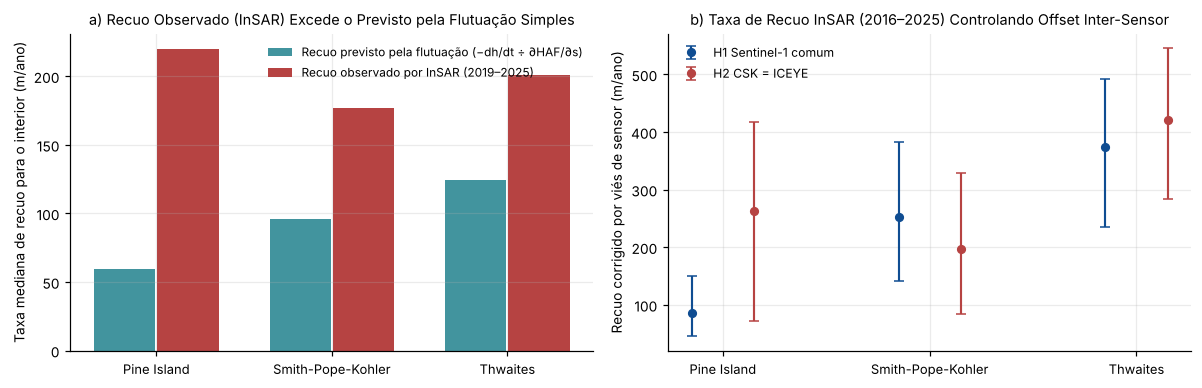

In [6]:
# 2. Comparação entre Recuo da Linha de Aterramento Previsto pela Flutuação (HAF) e Observado por InSAR
fig, ax = plt.subplots(1, 2, figsize=(11.0, 3.6))
x_g = np.arange(len(gl_prev))
ax[0].bar(x_g - 0.18, -gl_prev["v_prev"], width=0.35, color="#42949E", label="Recuo previsto pela flutuação (−dh/dt ÷ ∂HAF/∂s)")
ax[0].bar(x_g + 0.18, -gl_prev["v_obs"], width=0.35, color="#B64342", label="Recuo observado por InSAR (2019–2025)")
ax[0].set_xticks(x_g)
ax[0].set_xticklabels(gl_prev["geleira"], fontsize=8.5)
ax[0].set_ylabel("Taxa mediana de recuo para o interior (m/ano)")
ax[0].set_title("a) Recuo Observado (InSAR) Excede o Previsto pela Flutuação Simples")
ax[0].legend(frameon=False, fontsize=7.8)

for i, (hip, grp) in enumerate(gl_vies.groupby("hipotese")):
    col = "#0F4D92" if "H1" in hip else "#B64342"
    pos = np.arange(len(grp)) + (-0.15 if i == 0 else 0.15)
    ax[1].errorbar(pos, -grp["v_m_ano"], yerr=[-grp["v_m_ano"] - (-grp["hi"]), (-grp["lo"]) - (-grp["v_m_ano"])],
                   fmt="o", color=col, lw=1.4, ms=5, capsize=3, label=hip)
ax[1].set_xticks(range(3))
ax[1].set_xticklabels(["Pine Island", "Smith-Pope-Kohler", "Thwaites"], fontsize=8.5)
ax[1].set_ylabel("Recuo corrigido por viés de sensor (m/ano)")
ax[1].set_title("b) Taxa de Recuo InSAR (2016–2025) Controlando Offset Inter-Sensor")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

gl_prev[["geleira", "n_linhas", "haf_gl", "dhdt", "v_prev", "v_obs", "razao", "razao_lo", "razao_hi"]].set_index("geleira").round(2)

**Leitura da figura e da tabela.**
- **(a)** Nas três geleiras, o recuo observado por InSAR é maior que o previsto só pelo afinamento hidrostático: razões de 1,6 (Thwaites), 1,8 (SPK) e 3,7 (PIG). O IC da razão exclui 1 apenas na **Pine Island**; em SPK e Thwaites o limite inferior (~0,8) ainda admite recuo puramente hidrostático.
- **(b)** O recuo corrigido pelo desvio entre sensores depende da hipótese de ligação. A Thwaites é robusta (−375 a −421 m/ano nas duas hipóteses). Na PIG, a taxa triplica entre H1 e H2: a constelação SAR usada influencia mais o resultado que o próprio processo físico. A tabela de desvios abaixo mostra por quê: os sensores discordam em até ~1,4 km na mesma época.
- Um excesso de recuo sobre a previsão hidrostática é compatível com intrusão de água do mar na zona de aterramento (Rignot et al., 2024), mas com estes ICs não é uma prova.

In [7]:
desvios = pd.read_csv(DATA_DIR / "gl_migracao_desvios_sensor.csv")
display(desvios.pivot_table(index=["geleira", "hipotese"], columns="sensor", values="desvio_m").round(0))
gl_mare_ap.set_index(["grupo", "plataforma"]).round(3)

sensor                                 ALOS-2    CSK   ICEYE    RCM  SAOCOM  Sentinel-1  Sentinel-1 (Andersen 2025)  Sentinel-1 (CCI)
geleira           hipotese                                                                                                           
Pine Island       H1 Sentinel-1 comum     NaN  206.0 -1394.0    NaN     NaN         NaN                         NaN               NaN
                  H2 CSK = ICEYE          NaN    NaN     NaN    NaN     NaN       403.0                       660.0             -39.0
Smith-Pope-Kohler H1 Sentinel-1 comum   617.0 -750.0     NaN    NaN   269.0         NaN                         NaN               NaN
                  H2 CSK = ICEYE       1223.0    NaN     NaN    NaN   741.0      -169.0                       371.0             712.0
Thwaites          H1 Sentinel-1 comum     NaN  196.0   847.0  372.0  1063.0         NaN                         NaN               NaN
                  H2 CSK = ICEYE          NaN    NaN     NaN  375.0  1019.0       525.0                       315.0            -609.0

n  dist_mediana_GL_2019_2025_km  frac_a_menos_de_1km_GL_recente  dist_mediana_GL_ate_2011_km
grupo                  plataforma                                                                                                  
resposta_significativa Cosgrove      158                         8.444                           0.089                        9.039
                       Crosson       287                         1.779                           0.373                        5.949
                       Dotson        837                         5.663                           0.151                        7.392
                       Pine_Island   519                         4.291                           0.218                        8.079
                       Thwaites      448                         1.214                           0.475                        5.693
controle               Cosgrove     1978                         8.643                           0.050                        8.681
                       Crosson      1405                         3.539                           0.239                        7.897
                       Dotson       2721                         5.232                           0.151                        6.660
                       Pine_Island  3338                         6.665                           0.131                        8.461
                       Thwaites     1803                         3.162                           0.313                        7.625

**Leitura da resposta de maré no gelo "apoiado".**
- As células classificadas como apoiadas que respondem significativamente à maré (`resposta_significativa`) estão **mais perto da linha de aterramento recente** (2019–2025) do que da linha até 2011, e mais perto que as células de controle. Na Thwaites, 47% estão a menos de 1 km da linha recente.
- Interpretação: boa parte da "resposta de maré no apoiado" é gelo que **passou a flutuar** desde a delimitação antiga. A linha de aterramento recuou, e máscaras antigas classificam como apoiado o que hoje flexiona. Isso reforça o uso de máscaras recentes e do $d^*$ empírico (Caderno 05).

---

---
## 3. Dinâmica de Fraturamento em Fótons ATL03 e Rugosidade ATL06 na Margem da TEIS

A tabela abaixo apresenta o teste Lagrangiano de previsão por advecção pura versus observação para a densidade de fendas no ATL03 (`melange_fendas_atl03_advecao.csv`) e para a rugosidade superficial no ATL06 (`melange_rugosidade_atl06_advecao.csv`), demonstrando que na RGT 5 ($97{,}3\%$ do domínio material revisto) a densidade observada ($2{,}74\text{ fendas/km}$) concorda dentro do intervalo de confiança com a prevista pelo transporte de gelo já fraturado ($2{,}99\text{ fendas/km}$), enquanto na RGT 1079 (par 1) há excesso localizado de $+0{,}82\text{ fendas/km}$ (IC 95%: $+0{,}41$ a $+1{,}11$):

In [8]:
print("=== FENDAS EM FÓTONS ATL03: OBSERVADO VS. PREVISTO POR ADVECÇÃO MATERIAL ===")
print(mel_fendas.round(3).to_string(index=False))
print("\n=== RUGOSIDADE ATL06: OBSERVADO VS. PREVISTO POR ADVECÇÃO MATERIAL ===")
mel_rug.set_index(["pop", "faixa"]).round(3)

=== FENDAS EM FÓTONS ATL03: OBSERVADO VS. PREVISTO POR ADVECÇÃO MATERIAL ===
 rgt  par  km_2425_vistos  frac_vista  previsto  observado  obs_menos_prev     lo     hi  pass_1821  pass_2425
   5    1           72.60       0.973     2.994      2.741          -0.253 -1.331  1.007          5          4
1079    1           45.52       0.838     0.628      1.450           0.822  0.412  1.112          4          3
1079    2           18.40       1.000     3.894      0.217          -3.677 -6.869 -0.651          4          3

=== RUGOSIDADE ATL06: OBSERVADO VS. PREVISTO POR ADVECÇÃO MATERIAL ===


n_alvo  frac_com_ref    obs  previsto  obs_menos_prev     lo     hi  faixa_2019_20  desl_medio_km
pop             faixa                                                                                                      
f_grosso ≥ 0,72 margem      1113         0.604  3.686     3.281           0.405 -0.555  2.031          2.565          6.165
                interior    4491         0.838  3.217     2.620           0.596  0.141  1.372          3.190          4.551
só coesas       margem       937         0.604  3.230     2.843           0.387 -0.357  1.759          2.439          6.105
                interior    4021         0.819  2.712     2.388           0.324 -0.055  0.915          2.908          4.559

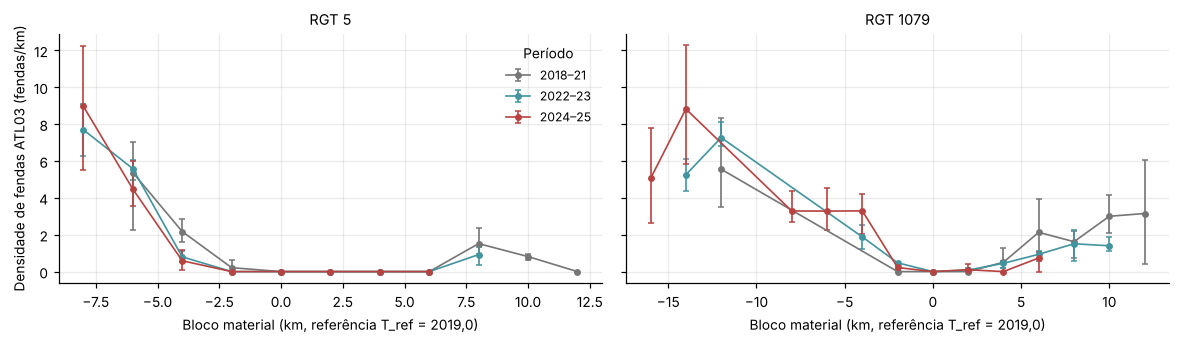

In [9]:
blocos = pd.read_csv(DATA_DIR / "melange_fendas_atl03_blocos.csv")
mat = blocos[blocos["ref"] == "material"]
fig, ax = plt.subplots(1, 2, figsize=(10.8, 3.2), sharey=True)
for i, rgt in enumerate([5, 1079]):
    for per, cor in [("2018–21", "#767676"), ("2022–23", "#42949E"), ("2024–25", "#B64342")]:
        g = mat[(mat["rgt"] == rgt) & (mat["periodo"] == per)].sort_values("bloco_km")
        ax[i].errorbar(g["bloco_km"], g["dens"], yerr=[g["dens"] - g["lo"], g["hi"] - g["dens"]],
                       fmt="o-", ms=3.5, capsize=2, color=cor, lw=1.1, label=per)
    ax[i].set_xlabel("Bloco material (km, referência T_ref = 2019,0)"); ax[i].set_title(f"RGT {rgt}")
ax[0].set_ylabel("Densidade de fendas ATL03 (fendas/km)"); ax[0].legend(frameon=False, fontsize=8, title="Período")
plt.tight_layout()

**Leitura do resultado.**
- **RGT 5 (97% do domínio material revisto):** a densidade observada em 2024–25 (2,74 fendas/km) é a prevista pelo simples transporte do gelo já fraturado (2,99; IC da diferença de −1,3 a +1,0). Nos blocos materiais, o perfil de fendas mantém a forma ao longo dos períodos: as fendas concentram-se nos blocos a montante (negativos) e o centro permanece livre. **Não há evidência de dano novo** nesse corredor.
- **RGT 1079, par 1:** excesso localizado de +0,82 fendas/km (IC 0,41–1,11) sobre a advecção, o único indício de fraturamento *in situ*. No par 2 ocorre o oposto (−3,7), compatível com cobertura parcial dos blocos mais fraturados.
- **Rugosidade ATL06:** o observado excede o previsto em +0,3 a +0,6. Na margem o IC contém zero; no interior, o excesso é significativo só na população de gelo grosso (+0,6; IC 0,14–1,37). É um sinal fraco de rugosidade adicional, coerente com dano novo localizado.
- Conclusão: o aumento de fraturamento na margem da TEIS é explicado **principalmente pela chegada de gelo já fraturado de montante**, com dano novo localizado e não generalizado.

---
## 4. Síntese do Caderno

| Pergunta | Resposta | Evidência |
|---|---|---|
| Os canais basais estão se aprofundando? | só na PIG lenta (IC > 0); Crosson e Dotson ficando rasos em agregado | efeito fixo de seção (§1) |
| A taxa de canal concorda com CryoSat-2 (Lowery)? | não, seção a seção ($\rho \approx 0{,}1$, sinal ~50%) | §1.1, resultado negativo |
| O recuo da linha é só hidrostático? | não na PIG (razão 3,7, IC > 1); inconclusivo em SPK e Thwaites | HAF × InSAR (§2) |
| O sensor SAR importa? | sim: desvios de até 1,4 km; a taxa da PIG triplica entre hipóteses | desvios por sensor (§2) |
| Maré no "apoiado"? | sobretudo gelo que passou a flutuar desde 2011 | distância à linha recente (§2) |
| Fraturamento novo na margem da TEIS? | majoritariamente advecção de gelo já fraturado; dano novo só local (RGT 1079) | blocos materiais ATL03 (§3) |

**Scripts do pipeline:** `pipelines/canais/c01..c07`, `pipelines/gl_migration/p01..p14`, `pipelines/melange/m01..m10`.

**Próximo caderno:** o Caderno 09 testa formalmente se as séries temporais mostram variabilidade, resposta a eventos e acoplamento climático.